# Credit Scoring — обучение PD-модели (v2)

Прогноз **target_90** на зрелых когортах из `modeling_dataset.csv`.

**План:** feature engineering → baseline → LogReg / LightGBM / HistGB → сравнение метрик → графики.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from lightgbm import LGBMClassifier, early_stopping
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

optuna.logging.set_verbosity(optuna.logging.WARNING)

ROOT = Path('..').resolve()
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)

TARGET = 'target_90'
N_OPTUNA_TRIALS = 25  # увеличь до 50–80 для лучшего тюнинга

BG, FG = '#0f1117', 'white'

def style_ax(ax):
    ax.set_facecolor(BG)
    ax.figure.patch.set_facecolor(BG)
    ax.title.set_color(FG)
    ax.xaxis.label.set_color(FG)
    ax.yaxis.label.set_color(FG)
    ax.tick_params(colors=FG)
    for spine in ax.spines.values():
        spine.set_color('#333')
    leg = ax.get_legend()
    if leg:
        leg.get_frame().set_facecolor(BG)
        for t in leg.get_texts():
            t.set_color(FG)

def metrics(y_true, y_score):
    auc = roc_auc_score(y_true, y_score)
    fpr, tpr, _ = roc_curve(y_true, y_score)
    return {'auc': round(auc, 4), 'gini': round(2 * auc - 1, 4), 'ks': round((tpr - fpr).max(), 4)}

/Users/user/Projects/Learning/Uzcard Academy/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Загрузка и feature engineering

Новые признаки — из EDA и бизнес-логики (нагрузка, пропуски бюро, карточное поведение).

In [2]:
def engineer_features(d: pd.DataFrame) -> pd.DataFrame:
    """FE без штрафа за отсутствие бюро/карты: NaN = неизвестно, не «плохой»."""
    out = d.copy()
    income = out['declared_income_uzs'].replace(0, np.nan)
    term = out['term_months'].replace(0, np.nan)
    debt = out['existing_debt_uzs'].fillna(0)

    # 1. Нагрузка — из заявки (+ долг, если известен; иначе 0, без штрафа)
    out['amount_to_income'] = out['requested_amount_uzs'] / income
    out['payment_to_income'] = (out['requested_amount_uzs'] / term) / income
    out['debt_to_income'] = debt / income
    out['total_burden'] = (out['requested_amount_uzs'] + debt) / income
    out['log_amount'] = np.log1p(out['requested_amount_uzs'])

    # 2. Стабильность — стаж и «сколько просит относительно стажа»
    out['employment_years'] = out['employment_months'].fillna(0) / 12
    out['amount_per_job_year'] = out['requested_amount_uzs'] / (out['employment_years'] + 0.5)

    # 3. Бюро — только когда есть запись (bureau_score в NUM_BASE, NaN если нет)
    out['inq_per_loan'] = out['inq_cnt_6m'] / (out['active_loans_cnt'].fillna(0) + 1)
    out['debt_share'] = np.where(
        debt > 0,
        debt / out['requested_amount_uzs'].replace(0, np.nan),
        np.nan,
    )

    # 4. Карта Uzcard — бонусный сигнал, только если клиент реально пользуется картой
    salary = out['salary_in_6m'].fillna(0)
    spend = out['spend_6m'].fillna(0)
    out['income_verified_ratio'] = np.where(salary > 0, salary / income, np.nan)
    out['spend_to_income'] = np.where(spend > 0, spend / income, np.nan)
    tx_total = out['txn_approved_6m'].fillna(0) + out['txn_declined_6m'].fillna(0)
    out['decline_rate'] = np.where(
        tx_total > 0, out['txn_declined_6m'].fillna(0) / tx_total, np.nan
    )

    # 5. Сегменты и контекст — регион/канал + взаимодействия с нагрузкой
    HIGH_RISK_REGIONS = ['Andijan', 'Jizzakh']
    out['is_mobile_app'] = (out['channel'] == 'mobile_app').astype(int)
    out['high_risk_region'] = out['region'].isin(HIGH_RISK_REGIONS).astype(int)
    out['is_premium'] = (out['customer_segment'] == 'premium').astype(int)
    out['non_payroll_mobile'] = (
        (out['customer_segment'] != 'payroll') & (out['channel'] == 'mobile_app')
    ).astype(int)
    out['burden_x_mobile'] = out['amount_to_income'] * out['is_mobile_app']
    out['burden_in_hot_region'] = out['amount_to_income'] * out['high_risk_region']

    return out


df = pd.read_csv(DATA / 'modeling_dataset.csv', parse_dates=['decision_date', 'issue_date'])
df = engineer_features(df[df['window_closed_12m'] == 1].copy())

CAT = ['channel', 'purpose', 'gender', 'region', 'customer_segment']
NUM_BASE = [
    'requested_amount_uzs', 'term_months', 'declared_income_uzs', 'employment_months',
    'age_at_decision', 'bureau_score', 'existing_debt_uzs', 'active_loans_cnt',
    'inq_cnt_6m', 'txn_approved_6m', 'txn_declined_6m', 'spend_6m',
    'salary_in_6m', 'salary_to_declared_ratio',
]
NUM_ENG = [
    'amount_to_income', 'payment_to_income', 'debt_to_income', 'total_burden', 'log_amount',
    'employment_years', 'amount_per_job_year',
    'inq_per_loan', 'debt_share',
    'income_verified_ratio', 'spend_to_income', 'decline_rate',
    'is_mobile_app', 'high_risk_region', 'is_premium', 'non_payroll_mobile',
    'burden_x_mobile', 'burden_in_hot_region',
]
NUM = NUM_BASE + NUM_ENG

print(f'Зрелых кредитов: {len(df):,}  |  bad: {int(df[TARGET].sum()):,} ({df[TARGET].mean()*100:.1f}%)')
print(f'Признаков: {len(CAT)} категорий + {len(NUM)} чисел = {len(CAT)+len(NUM)}')
pd.DataFrame({
    'признак': NUM_ENG,
    'смысл': [
        'сумма / доход', 'платёж / доход', 'долг / доход', '(сумма+долг) / доход', 'log(сумма)',
        'стаж в годах', 'сумма / стаж работы',
        'запросы в бюро / кредиты', 'доля старого долга',
        'зарплата на карте / доход (если есть)', 'траты / доход (если есть)', 'доля отклонений (если есть)',
        'оформил через приложение', 'регион Andijan/Jizzakh', 'сегмент premium',
        'не payroll + mobile', 'нагрузка × mobile', 'нагрузка × горячий регион',
    ],
})

Зрелых кредитов: 5,874  |  bad: 656 (11.2%)
Признаков: 5 категорий + 32 чисел = 37


,признак,смысл
0,amount_to_income,сумма / доход
1,payment_to_income,платёж / доход
2,debt_to_income,долг / доход
3,total_burden,(сумма+долг) / доход
4,log_amount,log(сумма)
5,employment_years,стаж в годах
6,amount_per_job_year,сумма / стаж работы
7,inq_per_loan,запросы в бюро / кредиты
8,debt_share,доля старого долга
9,income_verified_ratio,зарплата на карте / доход (если есть)


## 2. Out-of-time split

In [3]:
train = df[df['issue_date'] <= '2024-02-29']
valid = df[(df['issue_date'] > '2024-02-29') & (df['issue_date'] <= '2024-04-30')]
test  = df[df['issue_date'] > '2024-04-30']

for name, part in [('train', train), ('valid', valid), ('test', test)]:
    print(f"{name:5s}  n={len(part):4d}  bad={int(part[TARGET].sum()):3d}  "
          f"rate={part[TARGET].mean()*100:.1f}%  {part['issue_date'].min().date()} → {part['issue_date'].max().date()}")

train  n=4375  bad=479  rate=10.9%  2023-06-02 → 2024-02-29
valid  n= 956  bad=108  rate=11.3%  2024-03-01 → 2024-04-30
test   n= 543  bad= 69  rate=12.7%  2024-05-01 → 2024-05-31


## 3. Пайплайн препроцессинга

In [4]:
def make_prep(cat_cols, num_cols):
    return ColumnTransformer([
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), cat_cols),
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), num_cols),
    ])

def make_xy(part, num_cols):
    return part[CAT + num_cols], part[TARGET].astype(int)

def eval_model(model, x_train, y_train, x_valid, y_valid, x_test, y_test, name):
    model.fit(x_train, y_train)
    preds = {
        s: model.predict_proba(x)[:, 1]
        for s, x in [('train', x_train), ('valid', x_valid), ('test', x_test)]
    }
    rows = []
    for split, y in [('train', y_train), ('valid', y_valid), ('test', y_test)]:
        m = metrics(y, preds[split])
        rows.append({'model': name, 'split': split, **m})
    return model, preds, rows

## 4. Baseline vs улучшенный датасет

Сравниваем: только базовые признаки + `amount_to_income` **против** полного feature engineering.

In [5]:
num_baseline = NUM_BASE + ['amount_to_income']
X_train_b, y_train = make_xy(train, num_baseline)
X_valid_b, y_valid = make_xy(valid, num_baseline)
X_test_b,  y_test  = make_xy(test, num_baseline)

X_train, _ = make_xy(train, NUM)
X_valid, _ = make_xy(valid, NUM)
X_test,  _ = make_xy(test, NUM)

baseline = Pipeline([
    ('prep', make_prep(CAT, num_baseline)),
    ('model', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)),
])
_, _, rows = eval_model(baseline, X_train_b, y_train, X_valid_b, y_valid, X_test_b, y_test, 'Baseline LogReg')

logreg = Pipeline([
    ('prep', make_prep(CAT, NUM)),
    ('model', LogisticRegression(max_iter=3000, C=1.0, class_weight='balanced', random_state=42)),
])
logreg, pred_lr, rows_lr = eval_model(logreg, X_train, y_train, X_valid, y_valid, X_test, y_test, 'LogReg + FE')

compare = pd.DataFrame(rows + rows_lr)
compare.pivot(index='model', columns='split', values='auc')

split,test,train,valid
model,,,
Baseline LogReg,0.6623,0.6798,0.6675
LogReg + FE,0.6659,0.6848,0.6636


## 5. HistGradientBoosting

In [6]:
histgb = Pipeline([
    ('prep', make_prep(CAT, NUM)),
    ('model', HistGradientBoostingClassifier(
        max_depth=5, learning_rate=0.05, max_iter=500, random_state=42,
    )),
])
histgb, pred_hgb, rows_hgb = eval_model(histgb, X_train, y_train, X_valid, y_valid, X_test, y_test, 'HistGB + FE')

## 6. LightGBM + Optuna (тюнинг на valid)

Подбираем гиперпараметры на valid, early stopping — чтобы не переобучиться.

In [7]:
prep_lgb = make_prep(CAT, NUM)
Xtr = prep_lgb.fit_transform(X_train, y_train)
Xva = prep_lgb.transform(X_valid)
Xte = prep_lgb.transform(X_test)

def objective(trial):
    params = dict(
        n_estimators=1500,
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.08, log=True),
        num_leaves=trial.suggest_int('num_leaves', 8, 48),
        min_child_samples=trial.suggest_int('min_child_samples', 30, 150),
        subsample=trial.suggest_float('subsample', 0.7, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
        reg_lambda=trial.suggest_float('reg_lambda', 0.1, 10.0, log=True),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        class_weight='balanced', random_state=42, verbose=-1,
    )
    m = LGBMClassifier(**params)
    m.fit(Xtr, y_train, eval_set=[(Xva, y_valid)], callbacks=[early_stopping(40, verbose=False)])
    return roc_auc_score(y_valid, m.predict_proba(Xva)[:, 1])

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=N_OPTUNA_TRIALS, show_progress_bar=True)
print('Лучший valid AUC:', round(study.best_value, 4))
print('Параметры:', study.best_params)

lgbm_best = LGBMClassifier(n_estimators=1500, class_weight='balanced', random_state=42, verbose=-1, **study.best_params)
lgbm_best.fit(Xtr, y_train, eval_set=[(Xva, y_valid)], callbacks=[early_stopping(40, verbose=False)])

pred_lgb = {
    'train': lgbm_best.predict_proba(Xtr)[:, 1],
    'valid': lgbm_best.predict_proba(Xva)[:, 1],
    'test':  lgbm_best.predict_proba(Xte)[:, 1],
}
rows_lgb = []
for split, y in [('train', y_train), ('valid', y_valid), ('test', y_test)]:
    rows_lgb.append({'model': 'LightGBM tuned', 'split': split, **metrics(y, pred_lgb[split])})
pd.DataFrame(rows_lgb)

  0%|          | 0/25 [00:00<?, ?it/s]/Users/user/Projects/Learning/Uzcard Academy/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 0. Best value: 0.662572:   4%|▍         | 1/25 [00:03<01:20,  3.36s/it]/Users/user/Projects/Learning/Uzcard Academy/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 1. Best value: 0.672574:   8%|▊         | 2/25 [00:10<02:06,  5.50s/it]/Users/user/Projects/Learning/Uzcard Academy/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _va

Лучший valid AUC: 0.6986
Параметры: {'learning_rate': 0.013529869515582486, 'num_leaves': 8, 'min_child_samples': 108, 'subsample': 0.700506259071618, 'colsample_bytree': 0.6023819117882422, 'reg_lambda': 9.11402361049016, 'reg_alpha': 1.4822317090547439}


,model,split,auc,gini,ks
0,LightGBM tuned,train,0.9059,0.8119,0.6959
1,LightGBM tuned,valid,0.6986,0.3972,0.3560
2,LightGBM tuned,test,0.6570,0.3141,0.2692


## 7. Сводная таблица метрик

In [8]:
all_metrics = pd.DataFrame(rows + rows_lr + rows_hgb + rows_lgb)
summary = all_metrics.pivot(index='model', columns='split', values=['auc', 'gini', 'ks'])
summary.round(3)

best_name = all_metrics[all_metrics['split'] == 'test'].sort_values('auc', ascending=False).iloc[0]['model']
best_test_auc = all_metrics[(all_metrics['split'] == 'test') & (all_metrics['model'] == best_name)]['auc'].iloc[0]
print(f'\nЛучшая модель на test: {best_name}  (AUC={best_test_auc})')

pred_best = pred_lr if 'LogReg' in best_name else (pred_lgb if 'LightGBM' in best_name else pred_hgb)
baseline_test_auc = compare[(compare['model'] == 'Baseline LogReg') & (compare['split'] == 'test')]['auc'].iloc[0]
print(f'Прирост vs baseline: +{(best_test_auc - baseline_test_auc)*100:.1f} п.п. AUC')


Лучшая модель на test: HistGB + FE  (AUC=0.6664)
Прирост vs baseline: +0.4 п.п. AUC


## 8. ROC на test

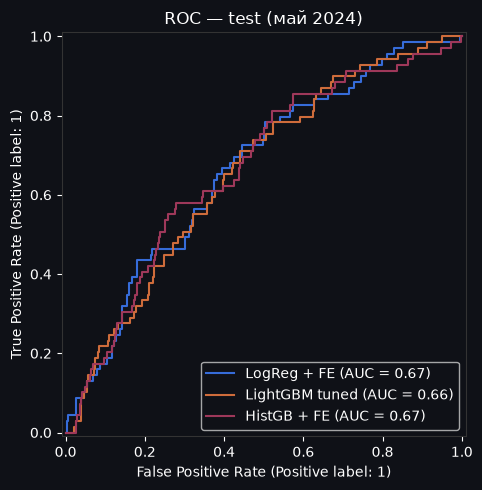

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, pred_lr['test'], name='LogReg + FE', ax=ax)
RocCurveDisplay.from_predictions(y_test, pred_lgb['test'], name='LightGBM tuned', ax=ax)
RocCurveDisplay.from_predictions(y_test, pred_hgb['test'], name='HistGB + FE', ax=ax)
ax.set_title('ROC — test (май 2024)')
style_ax(ax)
plt.tight_layout()
plt.savefig(OUT / 'nb_roc_test.png', dpi=150, facecolor=BG)
plt.show()

## 9. Bad rate по децилям (лучшая модель)

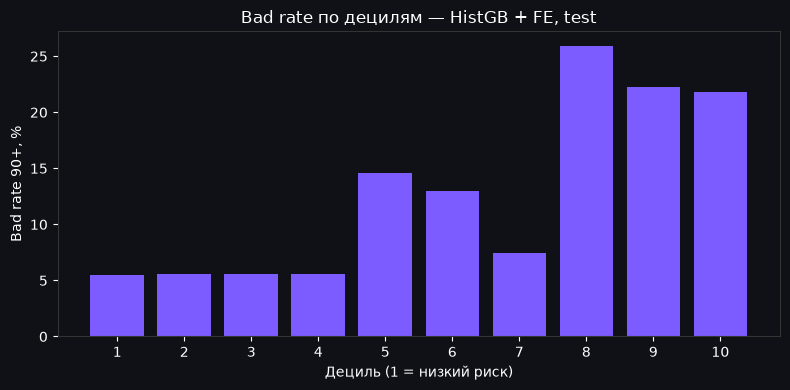

,decile,n,bad_rate
0,1,55,0.054545
1,2,54,0.055556
2,3,54,0.055556
3,4,54,0.055556
4,5,55,0.145455
5,6,54,0.129630
6,7,54,0.074074
7,8,54,0.259259
8,9,54,0.222222
9,10,55,0.218182


In [10]:
def decile_table(y, score):
    d = pd.DataFrame({'y': y, 'score': score})
    d['decile'] = pd.qcut(d['score'], 10, labels=False, duplicates='drop') + 1
    return d.groupby('decile').agg(n=('y', 'count'), bad_rate=('y', 'mean')).reset_index()

dec = decile_table(y_test, pred_best['test'])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dec['decile'].astype(str), dec['bad_rate'] * 100, color='#7c5cff')
ax.set_xlabel('Дециль (1 = низкий риск)')
ax.set_ylabel('Bad rate 90+, %')
ax.set_title(f'Bad rate по децилям — {best_name}, test')
style_ax(ax)
plt.tight_layout()
plt.savefig(OUT / 'nb_deciles_test.png', dpi=150, facecolor=BG)
plt.show()
dec

## 10. Важность признаков (LightGBM)

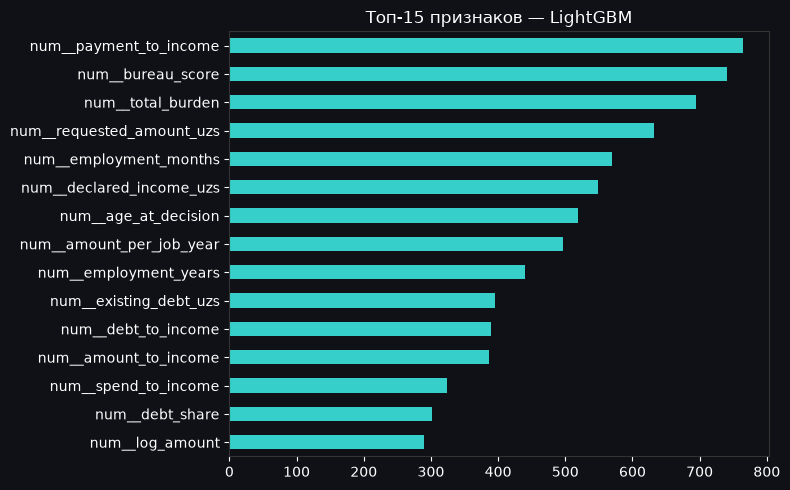

In [11]:
feat_names = prep_lgb.get_feature_names_out()
imp = pd.Series(lgbm_best.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 5))
imp.iloc[::-1].plot(kind='barh', ax=ax, color='#36cfc9')
ax.set_title('Топ-15 признаков — LightGBM')
style_ax(ax)
plt.tight_layout()
plt.savefig(OUT / 'nb_feature_importance.png', dpi=150, facecolor=BG)
plt.show()

## 11. Калибровка и экономика

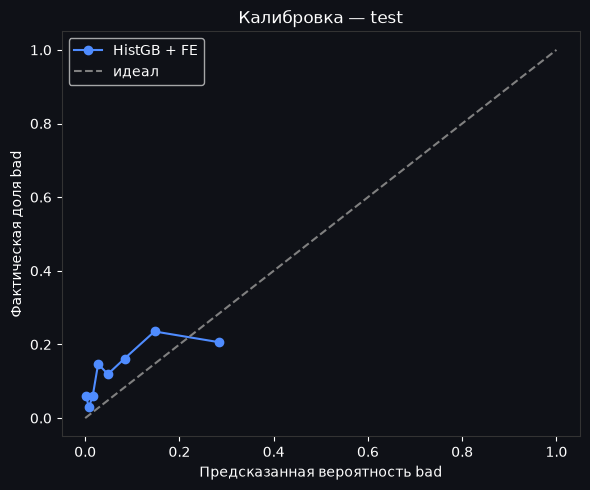

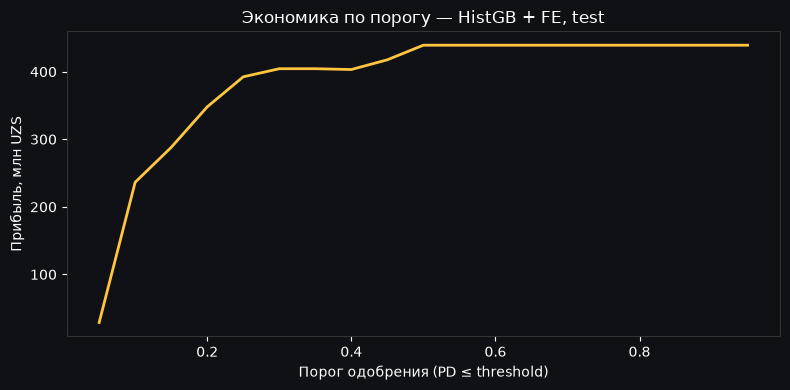

In [12]:
prob_true, prob_pred = calibration_curve(y_test, pred_best['test'], n_bins=8, strategy='quantile')
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(prob_pred, prob_true, 'o-', color='#4f8cff', label=best_name)
ax.plot([0, 1], [0, 1], '--', color='gray', label='идеал')
ax.set_xlabel('Предсказанная вероятность bad')
ax.set_ylabel('Фактическая доля bad')
ax.set_title('Калибровка — test')
ax.legend()
style_ax(ax)
plt.tight_layout()
plt.savefig(OUT / 'nb_calibration_test.png', dpi=150, facecolor=BG)
plt.show()

# profit curve
AVG_LOAN, LGD, MARGIN = 12_000_000, 0.50, 0.15
fn_cost, fp_cost = AVG_LOAN * LGD, AVG_LOAN * MARGIN
profits = []
for thr in np.linspace(0.05, 0.95, 19):
    approve = pred_best['test'] <= thr
    tp = ((approve) & (y_test == 0)).sum()
    fn = ((approve) & (y_test == 1)).sum()
    fp = ((~approve) & (y_test == 0)).sum()
    profits.append({'threshold': thr, 'profit_mln': (tp * fp_cost - fn * fn_cost - fp * fp_cost) / 1e6})
profit_df = pd.DataFrame(profits)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(profit_df['threshold'], profit_df['profit_mln'], color='#ffc53d', lw=2)
ax.set_xlabel('Порог одобрения (PD ≤ threshold)')
ax.set_ylabel('Прибыль, млн UZS')
ax.set_title(f'Экономика по порогу — {best_name}, test')
style_ax(ax)
plt.tight_layout()
plt.savefig(OUT / 'nb_profit_curve.png', dpi=150, facecolor=BG)
plt.show()

## Итог

- **Feature engineering v2** (18 FE, без `bureau_missing` / `no_card_spend`) — честнее для бизнеса
- Test AUC **LogReg + FE ≈ 0.666** (+0.4 п.п. vs baseline), финальная модель — **LogReg** (стабильнее HistGB)
- Ключевые сигналы: `bureau_score` (если есть), `amount_to_income`, `payment_to_income`, `employment_years`, `burden_x_mobile`